# 40-epoch screen: long-run stability and high-DockQ accuracy (full dataset)

Twenty-one runs: seven configurations $\times$ three seeds (7, 17, 27), 40 epochs each with the cosine learning-rate
schedule spread over all 40 (design: `LONG_SCREEN_FULL.md`). Every configuration is the control recipe (fixed loss
weights, reconstruction $\lambda=1$, dropout 0.3, capped inverse-sqrt range weighting, combined pooling) with
**one** change:

| config | change | question |
|---|---|---|
| control | none | reference |
| lambda3 | reconstruction $\lambda = 3$ | long-run stability |
| wd3e-2 | AdamW weight decay $3\times10^{-2}$ (was $10^{-5}$) | long-run stability |
| dropout05 | dropout 0.5 | long-run stability |
| hinge\_max\_b5 | DockQ weight 1 below 0.23 rising to $\beta=5$ at 1, on $\max(y,\hat y)$, mean-normalized; replaces range weighting | high-DockQ accuracy |
| capri\_head | + 4-class CAPRI head (softmax cross-entropy, weight 0.2); DockQ MSE kept | high-DockQ accuracy |
| rank | + within-target pairwise ranking loss (weight 0.1), batches of 4 targets $\times$ 4 decoys | high-DockQ accuracy |

Two questions: **(1)** does any change keep validation DockQ MSE falling over 40 epochs, and **(2)** does any change
make high-quality decoys (true DockQ $\geq 0.80$) predicted accurately without inflating poor ones?

Validation: 12 held-out targets (14,155 decoys), every 2,000 steps and at epoch ends; checkpoints are selected on
plain validation MSE. **The test split is untouched.** Figures use LaTeX Computer Modern, large labels, full
borders and no titles. Spreads are SD over seeds; paired intervals are bootstraps over the 12 validation targets.

In [1]:
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

if shutil.which('latex') is None:
    raise RuntimeError('LaTeX is required to render the figures in Computer Modern.')
GATE = Path.cwd() if (Path.cwd() / 'long_screen_full').is_dir() else Path.cwd() / 'gate_run'
ROOT = GATE / 'long_screen_full'
EXPORT = GATE / 'long_screen_full_analysis'; EXPORT.mkdir(exist_ok=True)
EPOCHS, SEEDS = 40, [7, 17, 27]
CONFIGS = ['control', 'lambda3', 'wd3e-2', 'dropout05', 'hinge_max_b5', 'capri_head', 'rank']
LABEL = {'control': 'Control', 'lambda3': r'$\lambda = 3$', 'wd3e-2': r'Weight decay $3\times10^{-2}$',
         'dropout05': 'Dropout 0.5', 'hinge_max_b5': r'Hinge, $\beta = 5$', 'capri_head': 'CAPRI head',
         'rank': 'Ranking loss'}
SHORT = {'control': 'Control', 'lambda3': r'$\lambda$=3', 'wd3e-2': 'WD', 'dropout05': 'Drop 0.5',
         'hinge_max_b5': 'Hinge', 'capri_head': 'CAPRI', 'rank': 'Rank'}
COLOR = {'control': '#000000', 'lambda3': '#56B4E9', 'wd3e-2': '#0072B2', 'dropout05': '#009E73',
         'hinge_max_b5': '#E69F00', 'capri_head': '#D55E00', 'rank': '#CC79A7'}
GROUP = {'control': 'reference', 'lambda3': 'stability', 'wd3e-2': 'stability', 'dropout05': 'stability',
         'hinge_max_b5': 'high DockQ', 'capri_head': 'high DockQ', 'rank': 'high DockQ'}
CAPRI = (0.23, 0.49, 0.80)
CAPRI_NAMES = ['incorrect', 'acceptable', 'medium', 'high']

mpl.rcParams.update({'text.usetex': True, 'font.family': 'serif', 'font.serif': ['Computer Modern Roman'],
    'mathtext.fontset': 'cm', 'axes.labelsize': 23, 'xtick.labelsize': 17, 'ytick.labelsize': 17,
    'legend.fontsize': 17, 'axes.spines.top': True, 'axes.spines.right': True, 'axes.linewidth': 1.1})

def save(fig, name):
    fig.savefig(EXPORT / (name + '.pdf'), bbox_inches='tight')
    fig.savefig(EXPORT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()

def run_dir(config, seed):
    return ROOT / f'{config}_seed{seed}'

steps, history, predictions, reports = [], [], {}, {}
for config in CONFIGS:
    for seed in SEEDS:
        d = run_dir(config, seed)
        s = pd.read_csv(d / 'validation_steps.csv').assign(config=config, seed=seed)
        h = pd.read_csv(d / 'loss_history.csv').assign(config=config, seed=seed)
        if h.epoch.max() != EPOCHS:
            raise ValueError(f'{d.name}: finished {h.epoch.max()} of {EPOCHS} epochs')
        # Epoch as a fraction of this run's own steps per epoch (grouped batching gives a few more batches).
        spe = s[(s.end_of_epoch == 1) & (s.epoch == 1)].global_step.iloc[0]
        s['epoch_float'] = s.global_step / spe
        p = pd.read_csv(d / 'validation_predictions.csv')
        mse = np.mean((p.predicted_target - p.true_target) ** 2)
        if not np.isclose(mse, s.val_target_mse.min(), rtol=1e-5, atol=1e-7):
            raise ValueError(f'{d.name}: exported predictions are not the best validation')
        steps.append(s); history.append(h); predictions[config, seed] = p
        reports[config, seed] = json.loads((d / 'prediction_metrics.json').read_text())['validation']
steps = pd.concat(steps, ignore_index=True); history = pd.concat(history, ignore_index=True)

reference = predictions['control', 7][['target_id', 'graph_name', 'true_target']]
for key, p in predictions.items():
    if not (p.graph_name.equals(reference.graph_name) and np.allclose(p.true_target, reference.true_target)):
        raise ValueError(f'{key}: validation cohort or labels differ')
CONST_MSE = reference.true_target.var(ddof=0)
targets = sorted(reference.target_id.unique())
print(f'{len(predictions)} runs, all {EPOCHS} epochs; identical validation cohort: {len(reference):,} decoys / '
      f'{len(targets)} targets.')
print(f'Exported predictions match the best step validation in every run. Constant-predictor MSE {CONST_MSE:.4f}.')

21 runs, all 40 epochs; identical validation cohort: 14,155 decoys / 12 targets.
Exported predictions match the best step validation in every run. Constant-predictor MSE 0.0903.


## Per-run metrics

At the **best checkpoint** (from `validation_predictions.csv`): validation MSE; macro within-target Spearman
$\langle\rho\rangle$; top-1 true DockQ; and the high-DockQ measures

- **high recall**: share of truly high decoys (DockQ $\geq 0.80$) predicted $\geq 0.80$,
- **high precision**: share of decoys predicted $\geq 0.80$ that are truly high,
- **high bias** / **low bias**: mean error on true high decoys and on incorrect decoys ($< 0.23$),
- **CAPRI accuracy**: CAPRI class of the predicted DockQ equals the true class.

Over **training** (from `validation_steps.csv`): epoch of the best checkpoint; **late** = mean validation MSE over
epochs 39--40; **slope** = validation MSE change per epoch over epochs 20--40 (from a straight-line fit; $\leq 0$
means still improving).

In [2]:
def capri_of(v):
    return np.searchsorted(CAPRI, v, side='right')

def checkpoint_metrics(p):
    y = p.true_target.to_numpy(); f = p.predicted_target.to_numpy(); hi = y >= .8; lo = y < .23; ph = f >= .8
    per_t = p.groupby('target_id')[['graph_name', 'true_target', 'predicted_target']].apply(lambda g: pd.Series(dict(
        rho=spearmanr(g.true_target, g.predicted_target).statistic,
        top1=g.true_target.to_numpy()[np.lexsort((g.graph_name.to_numpy(), -g.predicted_target.to_numpy()))[0]],
        mse=np.mean((g.predicted_target - g.true_target) ** 2))))
    return dict(mse=np.mean((f - y) ** 2), macro_rho=per_t.rho.mean(), top1=per_t.top1.mean(),
                high_recall=ph[hi].mean(), high_precision=hi[ph].mean() if ph.any() else np.nan,
                n_pred_high=int(ph.sum()), high_bias=(f - y)[hi].mean(), high_mse=((f - y) ** 2)[hi].mean(),
                low_bias=(f - y)[lo].mean(), capri_acc=(capri_of(f) == capri_of(y)).mean(),
                high_auc_scalar=roc_auc_score(hi, f)), per_t

rows, per_target = [], []
for (config, seed), p in predictions.items():
    m, per_t = checkpoint_metrics(p)
    s = steps[(steps.config == config) & (steps.seed == seed)].sort_values('global_step')
    b = s.loc[s.val_target_mse.idxmin()]
    w = s[s.epoch_float > 20]
    m.update(best_epoch=b.epoch_float, late=s[s.epoch > EPOCHS - 2].val_target_mse.mean(),
             slope_20_40=np.polyfit(w.epoch_float, w.val_target_mse, 1)[0],
             train_mse_end=history[(history.config == config) & (history.seed == seed)].train_target_mse.iloc[-1])
    if 'p_high' in p:
        m['high_auc_p_high'] = roc_auc_score(p.true_target >= .8, p.p_high)
    rows.append(dict(config=config, seed=seed, **m))
    per_target.append(per_t.reset_index().assign(config=config, seed=seed))
metrics = pd.DataFrame(rows); per_target = pd.concat(per_target, ignore_index=True)
metrics.to_csv(EXPORT / 'metrics_per_run.csv', index=False); per_target.to_csv(EXPORT / 'metrics_per_target.csv', index=False)

COLS = ['mse', 'late', 'slope_20_40', 'best_epoch', 'macro_rho', 'top1', 'high_recall', 'high_precision',
        'n_pred_high', 'high_bias', 'high_mse', 'low_bias', 'capri_acc', 'train_mse_end']
agg = metrics.groupby('config')[COLS].agg(['mean', 'std']).loc[CONFIGS]
agg.to_csv(EXPORT / 'metrics_by_config.csv')
display(metrics.groupby('config')[COLS].mean().loc[CONFIGS].round(4))

,mse,late,slope_20_40,best_epoch,macro_rho,top1,high_recall,high_precision,n_pred_high,high_bias,high_mse,low_bias,capri_acc,train_mse_end
config,,,,,,,,,,,,,,
control,0.0482,0.0585,0.0000,6.5098,0.7048,0.5358,0.0115,0.5728,27.0000,-0.3068,0.1215,0.1456,0.5472,0.0211
lambda3,0.0506,0.0562,0.0001,15.7737,0.6916,0.5157,0.0411,0.3296,90.3333,-0.3173,0.1282,0.1539,0.5468,0.0285
wd3e-2,0.0481,0.0578,0.0001,10.0985,0.7132,0.4858,0.0860,0.7857,173.0000,-0.2966,0.1156,0.1398,0.5610,0.0222
dropout05,0.0567,0.0630,0.0000,9.0115,0.6754,0.4235,0.0000,NaN,0.0000,-0.3728,0.1653,0.1799,0.4760,0.0358
hinge_max_b5,0.0498,0.0608,0.0001,3.2539,0.7136,0.4005,0.0581,0.6013,94.6667,-0.3003,0.1158,0.1747,0.4911,0.0252
capri_head,0.0462,0.0761,0.0002,2.9210,0.7241,0.4966,0.0860,0.7609,342.0000,-0.2565,0.0925,0.1439,0.5631,0.0145
rank,0.0465,0.0591,0.0001,9.0023,0.7319,0.4898,0.0480,0.9271,73.6667,-0.2919,0.1116,0.1419,0.5552,0.0182


## Question 1: does validation keep falling over 40 epochs?

Validation DockQ MSE over training for every configuration (thin: seeds; thick: seed mean), with the control's
mean repeated in grey. The dot marks the mean curve's minimum.

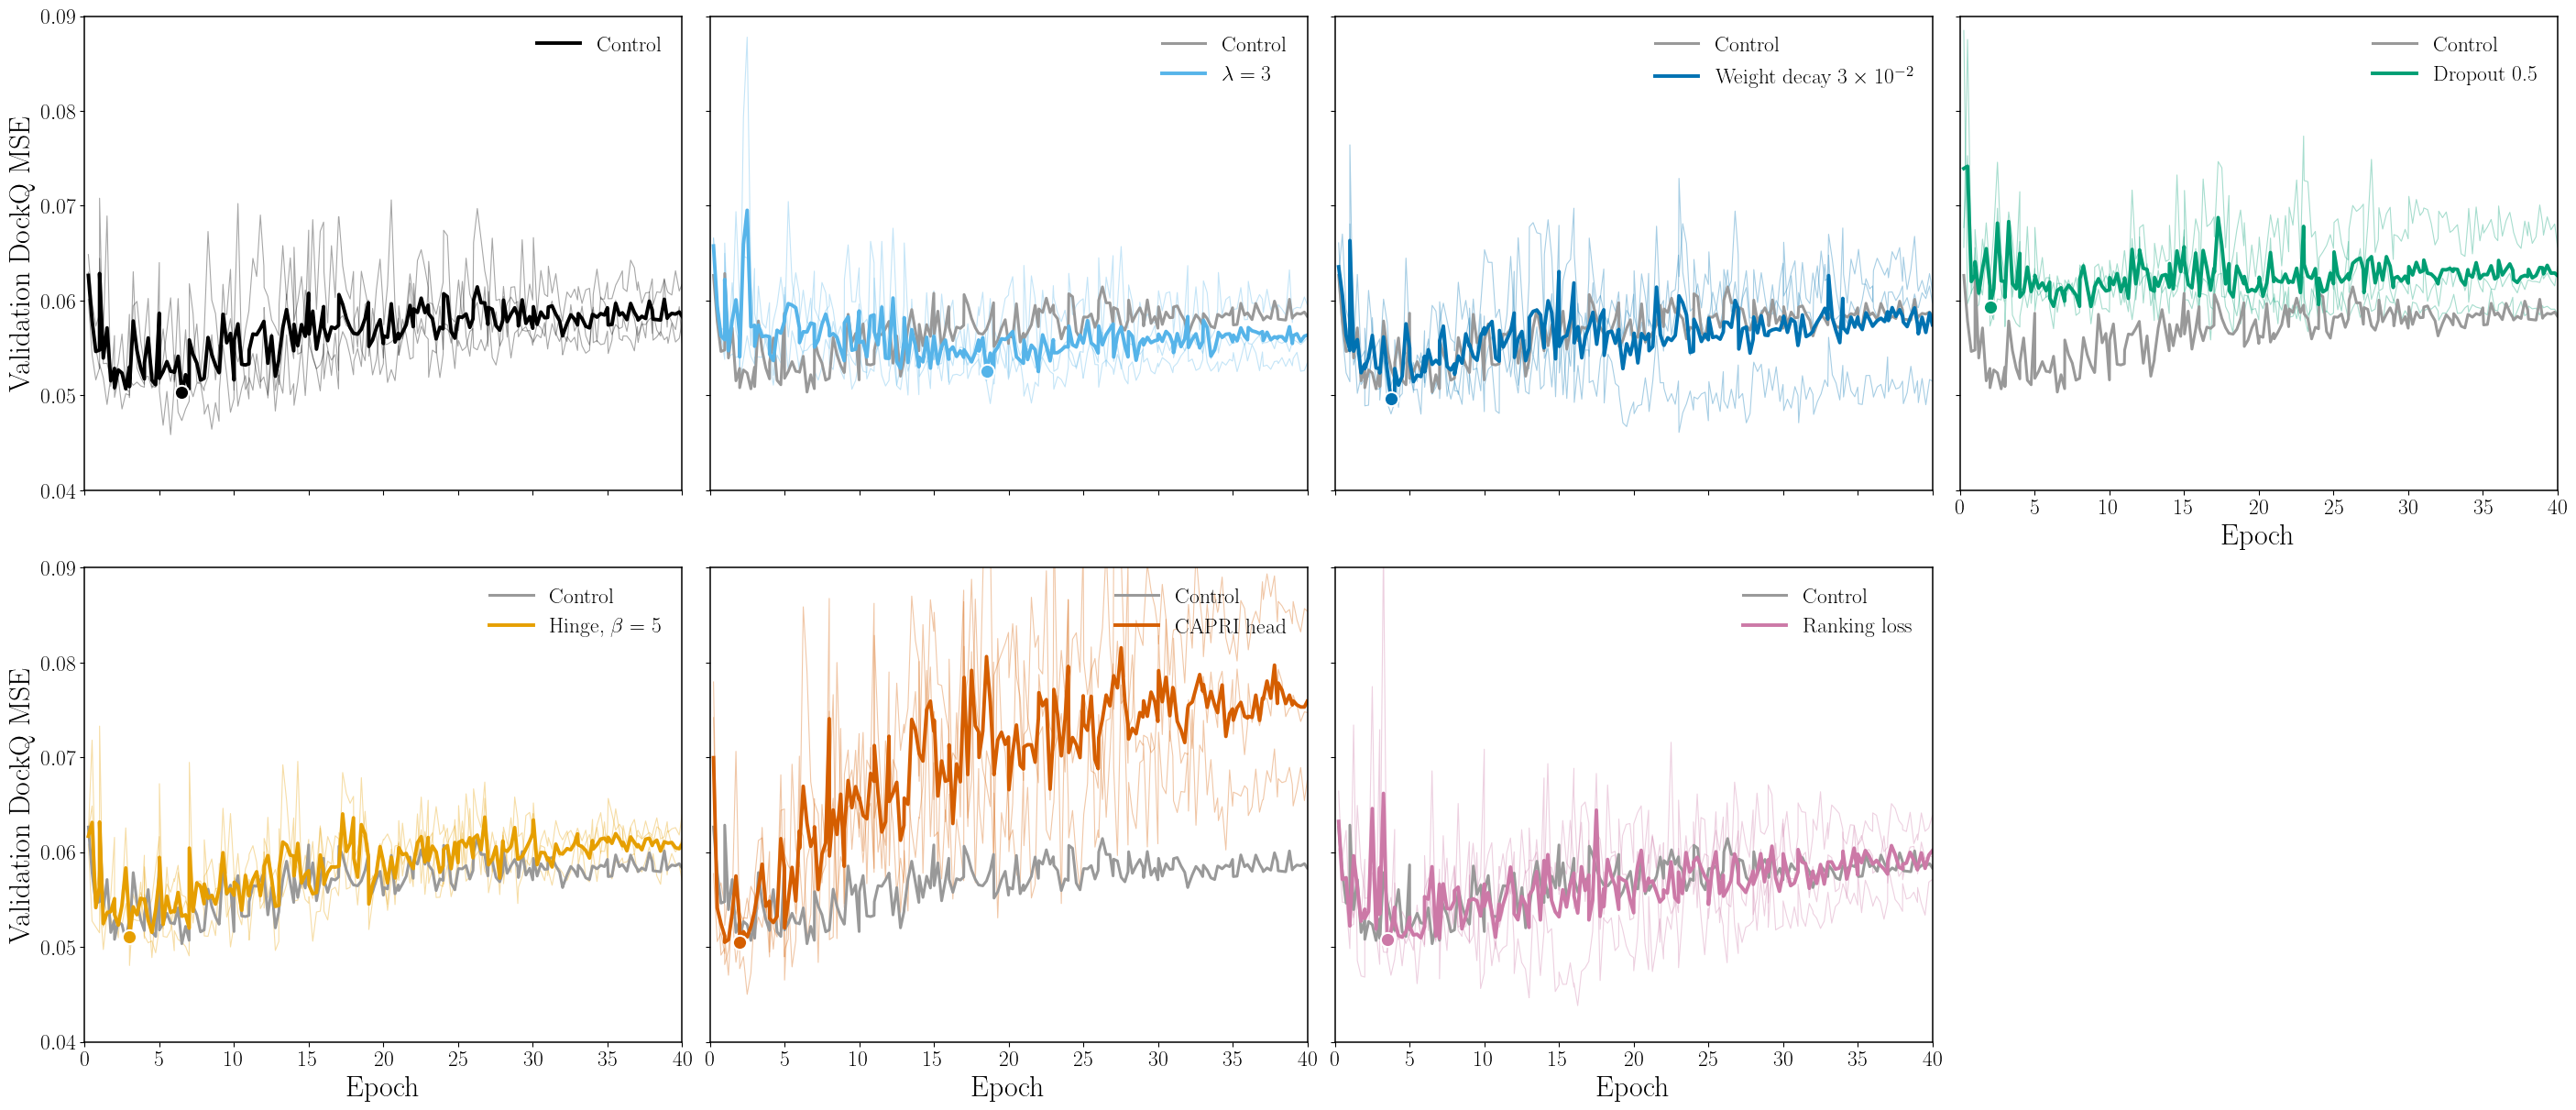

In [3]:
ctrl = steps[steps.config == 'control'].groupby('global_step').agg(x=('epoch_float', 'mean'), y=('val_target_mse', 'mean'))
fig, axes = plt.subplots(2, 4, figsize=(28, 12), sharex=True, sharey=True, constrained_layout=True)
for ax, config in zip(axes.flat, CONFIGS):
    for seed in SEEDS:
        r = steps[(steps.config == config) & (steps.seed == seed)].sort_values('global_step')
        ax.plot(r.epoch_float, r.val_target_mse, color=COLOR[config], lw=0.8, alpha=0.35)
    m = steps[steps.config == config].groupby('global_step').agg(x=('epoch_float', 'mean'), y=('val_target_mse', 'mean'))
    if config != 'control':
        ax.plot(ctrl.x, ctrl.y, color='0.6', lw=2.2, label='Control')
    ax.plot(m.x, m.y, color=COLOR[config], lw=2.8, label=LABEL[config])
    i = m.y.idxmin(); ax.plot(m.x[i], m.y[i], 'o', ms=11, color=COLOR[config], mec='white', mew=1.5, zorder=5)
    ax.set_xlim(0, EPOCHS); ax.set_ylim(0.04, 0.09)
    ax.legend(frameon=False, loc='upper right', fontsize=17)
axes.flat[-1].set_visible(False)
for ax in axes[-1]: ax.set_xlabel('Epoch')
axes[0, -1].tick_params(labelbottom=True); axes[0, -1].set_xlabel('Epoch')
for ax in axes[:, 0]: ax.set_ylabel('Validation DockQ MSE')
save(fig, 'validation_curves_by_config')

Best validation MSE (solid) and end-of-training MSE (hatched, mean of epochs 39--40) per configuration;
the gap is how much each configuration gives back by the end of a 40-epoch run. Right: the slope over epochs
20--40, where a value at or below zero would mean validation was still improving.

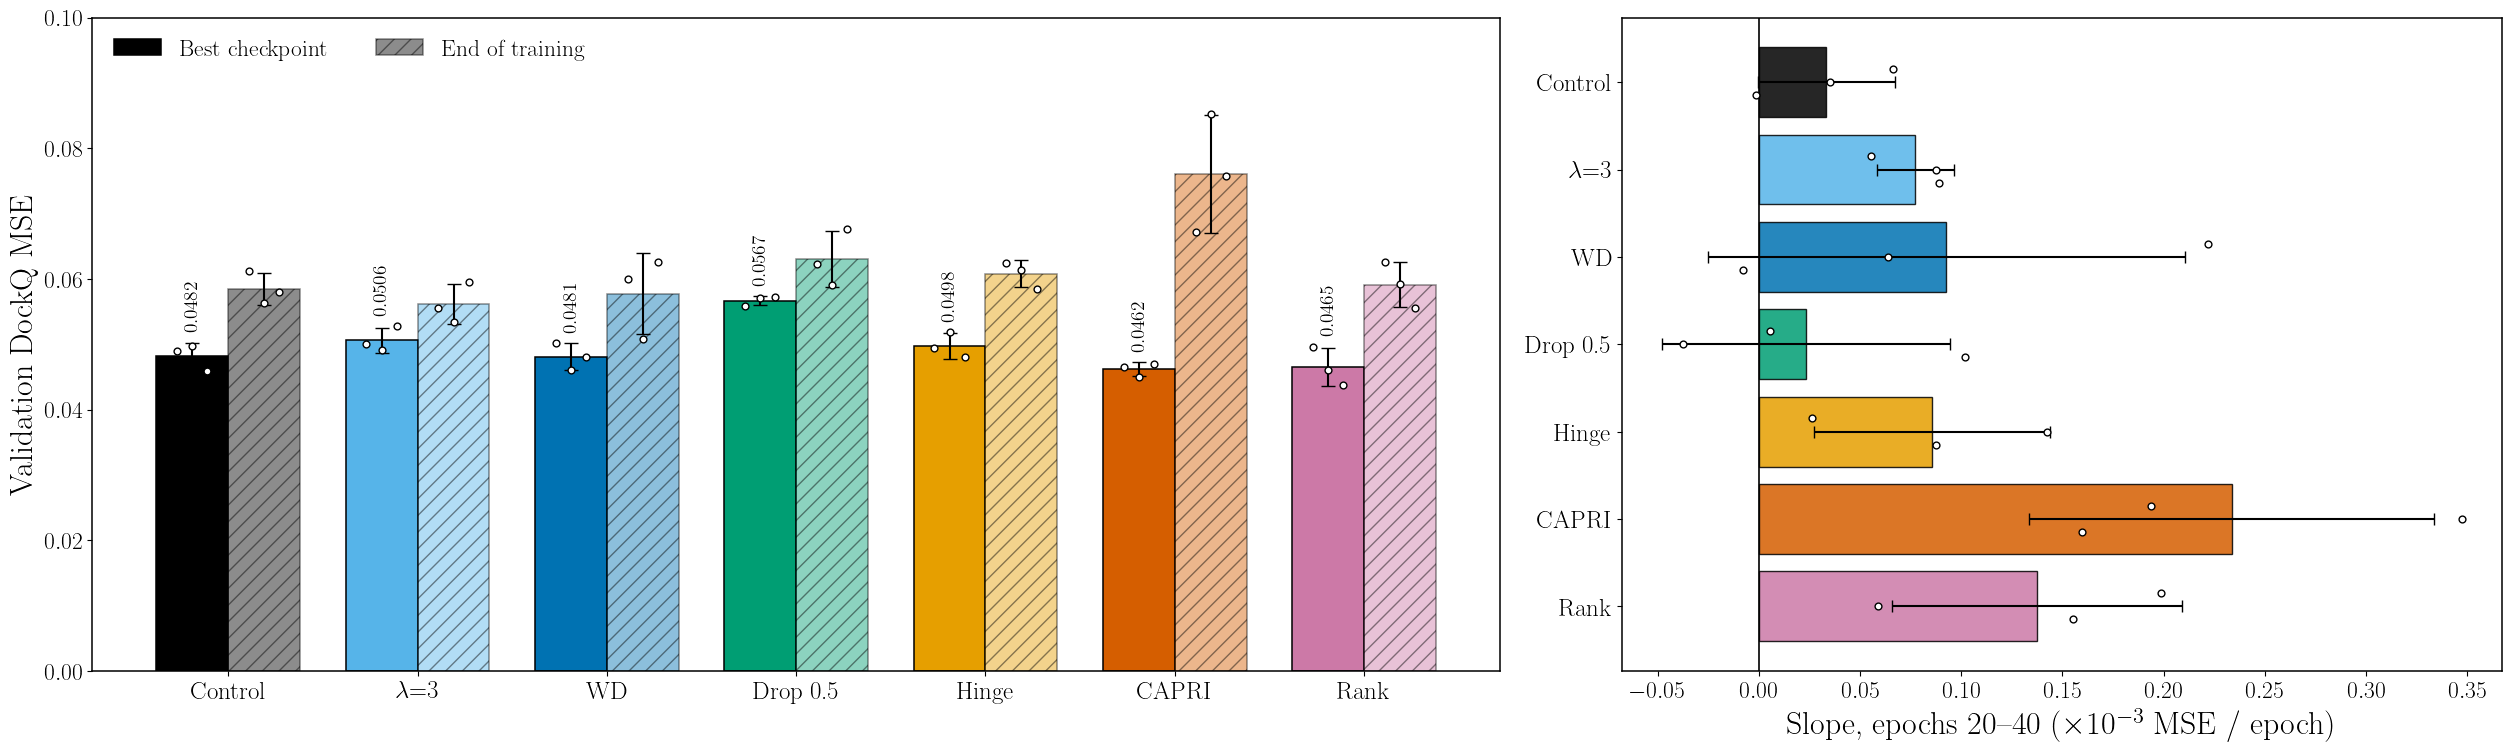

In [4]:
x = np.arange(len(CONFIGS)); w = .38
fig, (ax, axs) = plt.subplots(1, 2, figsize=(25, 7.4), gridspec_kw=dict(width_ratios=[1.6, 1]), constrained_layout=True)
for k, (col, hatch, alpha, lab) in enumerate([('mse', None, 1, 'Best checkpoint'), ('late', '//', .45, 'End of training')]):
    v = agg[(col, 'mean')].to_numpy(); e = agg[(col, 'std')].to_numpy()
    ax.bar(x + (k - .5) * w, v, w, yerr=e, capsize=5, color=[COLOR[c] for c in CONFIGS], alpha=alpha, hatch=hatch,
           edgecolor='black', lw=1.1, label=lab)
    for i, c in enumerate(CONFIGS):
        sv = metrics.loc[metrics.config == c, col].to_numpy()
        ax.scatter(x[i] + (k - .5) * w + np.linspace(-.08, .08, 3), sv, s=24, zorder=6, facecolors='white', edgecolors='black')
        if col == 'mse':
            ax.text(x[i] + (k - .5) * w, max(v[i] + e[i], sv.max()) + .0015, f'{v[i]:.4f}', ha='center', fontsize=14,
                    rotation=90, va='bottom')
ax.set_xticks(x, [SHORT[c] for c in CONFIGS], fontsize=18); ax.set_ylabel('Validation DockQ MSE')
ax.set_ylim(0, .1); ax.legend(frameon=False, loc='upper left', ncol=2, fontsize=17)
v = agg[('slope_20_40', 'mean')] * 1e3; e = agg[('slope_20_40', 'std')] * 1e3
axs.barh(x[::-1], v, xerr=e, color=[COLOR[c] for c in CONFIGS], edgecolor='black', capsize=4, alpha=.85)
for i, c in enumerate(CONFIGS):
    sv = metrics.loc[metrics.config == c, 'slope_20_40'].to_numpy() * 1e3
    axs.scatter(sv, x[::-1][i] + np.linspace(-.15, .15, 3), s=24, zorder=6, facecolors='white', edgecolors='black')
axs.axvline(0, color='black', lw=1.2)
axs.set_yticks(x[::-1], [SHORT[c] for c in CONFIGS], fontsize=18)
axs.set_xlabel(r'Slope, epochs 20--40 ($\times10^{-3}$ MSE / epoch)')
save(fig, 'best_vs_end_and_slope')

## Paired comparison against the control (best checkpoints)

Per validation target, each metric is averaged over seeds and differenced against the control; the 12 differences
are bootstrapped (10,000 resamples) for a 95\% interval. Positive favours the configuration in every panel.
Numbers on the right count the targets where it beat the control.

,config,metric,mean,lo,hi,wins,n
0,lambda3,mse,-0.0026,-0.0061,0.0008,2,12
1,lambda3,rho,-0.0132,-0.0430,0.0115,5,12
2,lambda3,top1,-0.0201,-0.1072,0.0693,5,12
3,wd3e-2,mse,0.0008,-0.0025,0.0053,5,12
4,wd3e-2,rho,0.0084,-0.0149,0.0376,5,12
5,wd3e-2,top1,-0.0500,-0.1270,0.0378,4,12
6,dropout05,mse,-0.0073,-0.0147,-0.0003,3,12
7,dropout05,rho,-0.0294,-0.0790,0.0142,4,12
8,dropout05,top1,-0.1123,-0.2013,-0.0372,2,12
9,hinge_max_b5,mse,-0.0002,-0.0056,0.0065,3,12


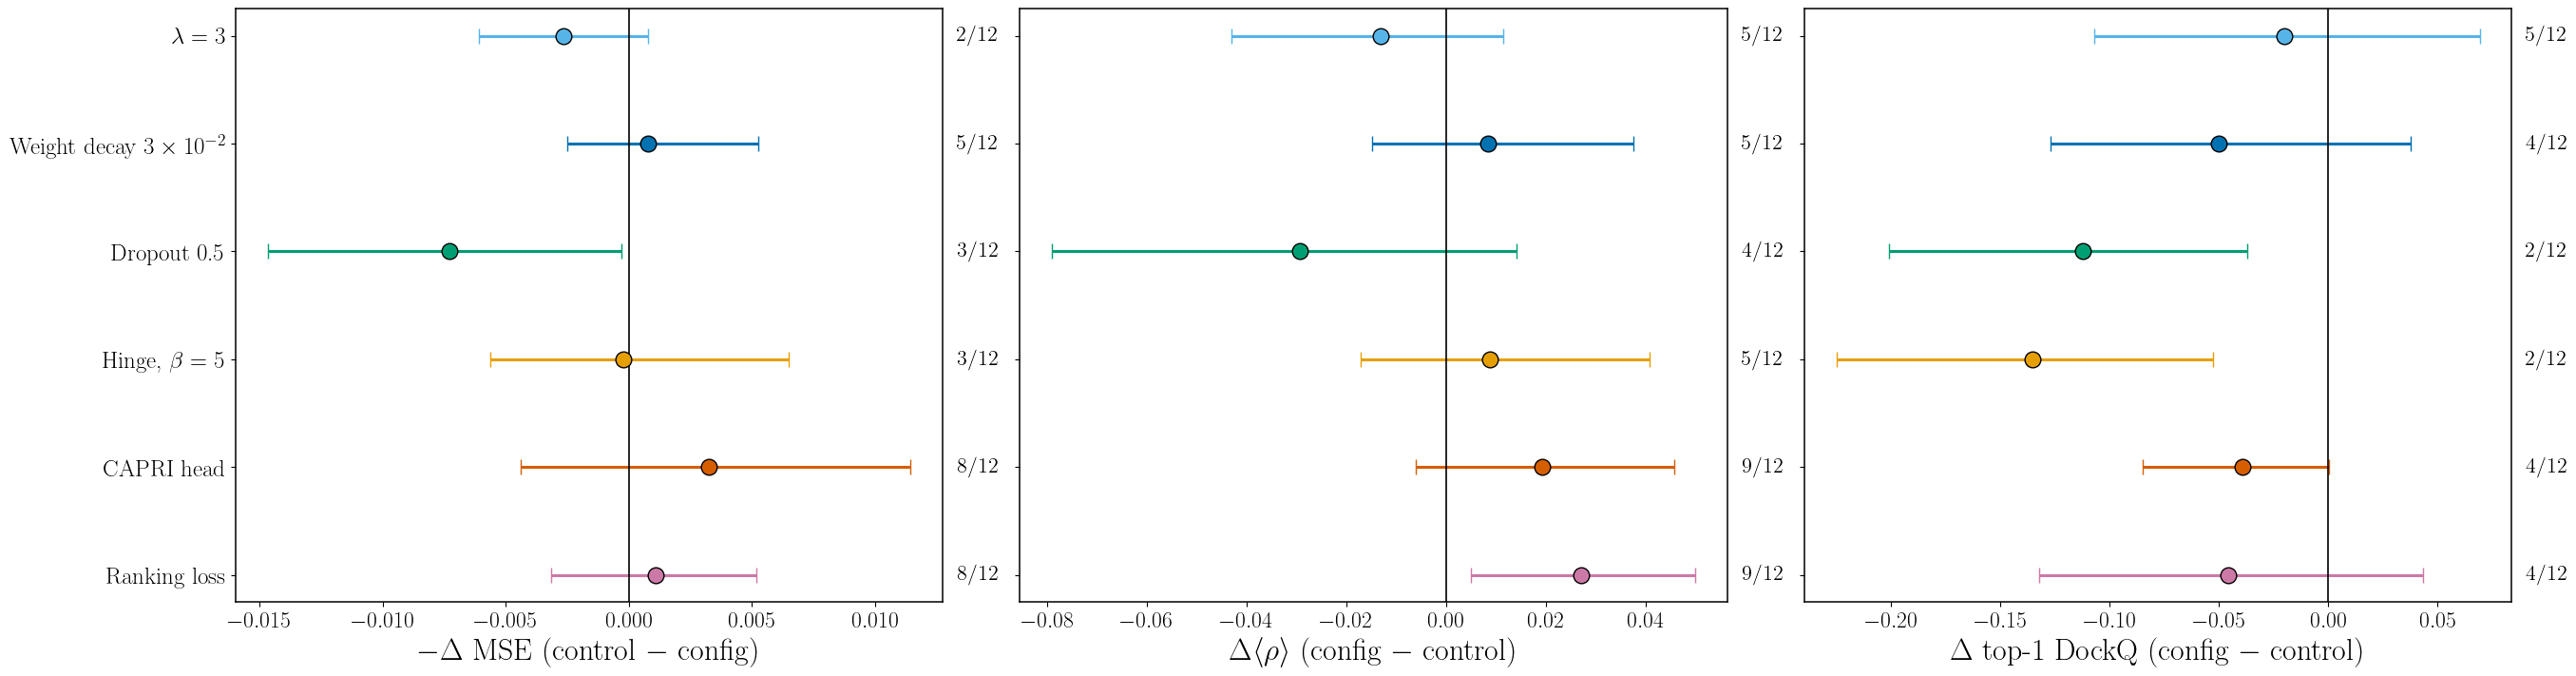

In [5]:
rng = np.random.default_rng(0)
seed_mean = per_target.groupby(['config', 'target_id'])[['mse', 'rho', 'top1']].mean()
eff = []
for config in CONFIGS[1:]:
    for metric, sign in [('mse', -1), ('rho', 1), ('top1', 1)]:
        d = sign * (seed_mean.loc[config, metric] - seed_mean.loc['control', metric]).to_numpy()
        boots = rng.choice(d, size=(10_000, len(d))).mean(1)
        eff.append(dict(config=config, metric=metric, mean=d.mean(), lo=np.percentile(boots, 2.5),
                        hi=np.percentile(boots, 97.5), wins=int((d > 0).sum()), n=len(d)))
eff = pd.DataFrame(eff); eff.to_csv(EXPORT / 'paired_vs_control.csv', index=False); display(eff.round(4))

fig, axes = plt.subplots(1, 3, figsize=(27, 7), sharey=True, constrained_layout=True)
yp = np.arange(len(CONFIGS) - 1)[::-1]
for ax, metric, xlabel in [(axes[0], 'mse', r'$-\Delta$ MSE (control $-$ config)'),
                           (axes[1], 'rho', r'$\Delta\langle\rho\rangle$ (config $-$ control)'),
                           (axes[2], 'top1', r'$\Delta$ top-1 DockQ (config $-$ control)')]:
    e = eff[eff.metric == metric].set_index('config').loc[CONFIGS[1:]]
    for yv, (config, r) in zip(yp, e.iterrows()):
        ax.errorbar(r['mean'], yv, xerr=[[r['mean'] - r.lo], [r.hi - r['mean']]], fmt='o', ms=12, capsize=6, lw=2.2,
                    color=COLOR[config], mec='black')
        ax.text(1.02, yv, f'{r.wins}/{r.n}', transform=ax.get_yaxis_transform(), va='center', fontsize=16)
    ax.axvline(0, color='black', lw=1.2); ax.set_xlabel(xlabel)
axes[0].set_yticks(yp, [LABEL[c] for c in CONFIGS[1:]], fontsize=18)
save(fig, 'paired_vs_control')

## Question 2: high-DockQ accuracy

Left: mean prediction error by true CAPRI class (seed mean). Middle: **recall** of high-quality decoys (share of
true highs predicted $\geq 0.80$) against **precision** (share of predicted highs that are truly high); point size
is the number of decoys predicted $\geq 0.80$; seeds are small points, configuration means large. Right: CAPRI-class
accuracy of the DockQ prediction.

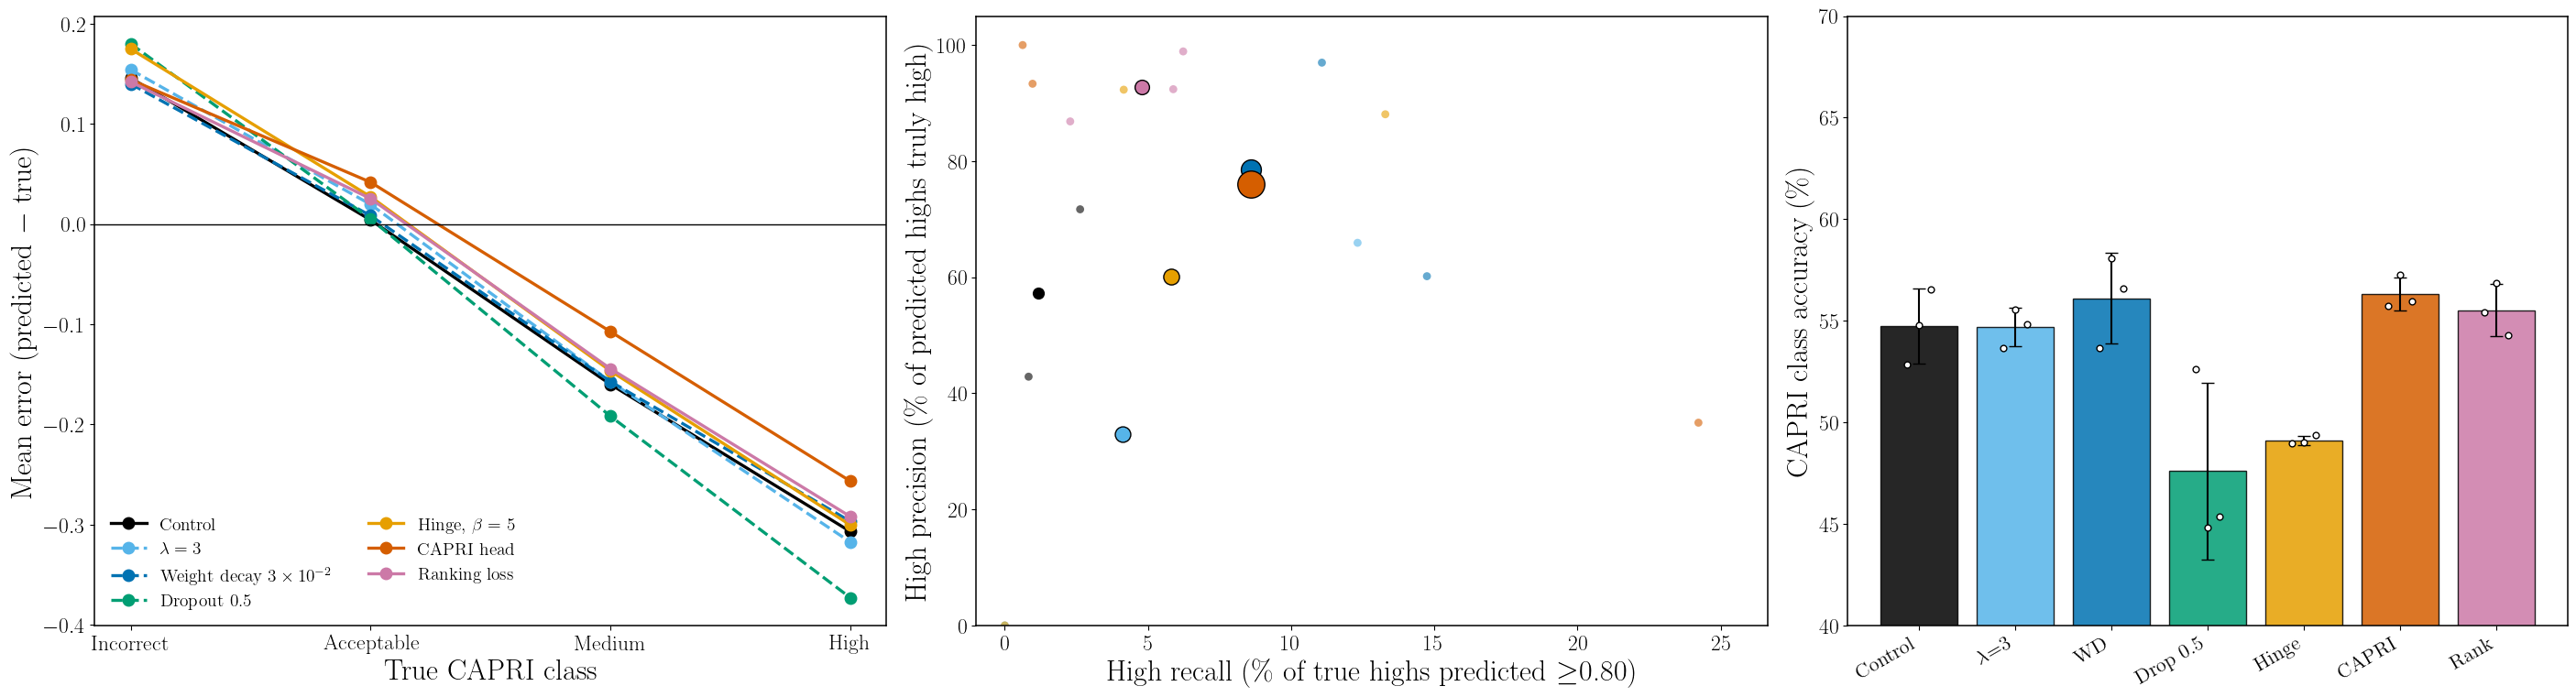

,high_recall,high_precision,n_pred_high,high_bias,low_bias,capri_acc,high_auc_scalar
config,,,,,,,
control,0.012,0.573,27.000,-0.307,0.146,0.547,0.839
lambda3,0.041,0.330,90.333,-0.317,0.154,0.547,0.819
wd3e-2,0.086,0.786,173.000,-0.297,0.140,0.561,0.843
dropout05,0.000,NaN,0.000,-0.373,0.180,0.476,0.799
hinge_max_b5,0.058,0.601,94.667,-0.300,0.175,0.491,0.843
capri_head,0.086,0.761,342.000,-0.257,0.144,0.563,0.843
rank,0.048,0.927,73.667,-0.292,0.142,0.555,0.838


In [6]:
bias_rows = []
for (config, seed), p in predictions.items():
    cls = capri_of(p.true_target.to_numpy()); err = (p.predicted_target - p.true_target).to_numpy()
    for k, name in enumerate(CAPRI_NAMES):
        bias_rows.append(dict(config=config, seed=seed, cls=k, bias=err[cls == k].mean(), mse=(err[cls == k] ** 2).mean()))
bias = pd.DataFrame(bias_rows); bias.to_csv(EXPORT / 'capri_class_errors.csv', index=False)
bm = bias.groupby(['config', 'cls'])[['bias', 'mse']].mean().reset_index()

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(28, 7.5), gridspec_kw=dict(width_ratios=[1.1, 1.1, 1]),
                                 constrained_layout=True)
for config in CONFIGS:
    b = bm[bm.config == config]
    a1.plot(b.cls, b.bias, marker='o', ms=9, lw=2.4, color=COLOR[config], label=LABEL[config],
            ls='-' if GROUP[config] != 'stability' else '--')
a1.axhline(0, color='black', lw=1)
a1.set_xticks(range(4), [n.capitalize() for n in CAPRI_NAMES]); a1.set_xlabel('True CAPRI class')
a1.set_ylabel(r'Mean error (predicted $-$ true)'); a1.legend(frameon=False, fontsize=14, loc='lower left', ncol=2)

for config in CONFIGS:
    r = metrics[metrics.config == config]
    a2.scatter(r.high_recall * 100, r.high_precision * 100, s=40, color=COLOR[config], alpha=.6, edgecolors='none')
    a2.scatter(r.high_recall.mean() * 100, r.high_precision.mean() * 100, s=40 + 1.2 * r.n_pred_high.mean(),
               color=COLOR[config], edgecolors='black', zorder=5)
a2.set_xlabel(r'High recall (\% of true highs predicted $\geq$0.80)')
a2.set_ylabel(r'High precision (\% of predicted highs truly high)')
a2.set_xlim(-1, max(15, metrics.high_recall.max() * 110)); a2.set_ylim(0, 105)

v = agg[('capri_acc', 'mean')] * 100; e = agg[('capri_acc', 'std')] * 100
a3.bar(np.arange(len(CONFIGS)), v, yerr=e, capsize=5, color=[COLOR[c] for c in CONFIGS], edgecolor='black', alpha=.85)
for i, c in enumerate(CONFIGS):
    sv = metrics.loc[metrics.config == c, 'capri_acc'].to_numpy() * 100
    a3.scatter(i + np.linspace(-.12, .12, 3), sv, s=24, zorder=6, facecolors='white', edgecolors='black')
a3.set_xticks(np.arange(len(CONFIGS)), [SHORT[c] for c in CONFIGS], rotation=30, ha='right', fontsize=16)
a3.set_ylabel(r'CAPRI class accuracy (\%)'); a3.set_ylim(40, 70)
save(fig, 'high_dockq_accuracy')
display(metrics.groupby('config')[['high_recall', 'high_precision', 'n_pred_high', 'high_bias', 'low_bias',
                                    'capri_acc', 'high_auc_scalar']].mean().loc[CONFIGS].round(3))

### Does the CAPRI head's P(high) find the high-quality decoys?

The CAPRI head outputs a probability that each decoy is high quality. Left: how well P(high) separates true highs
from everything else (ROC AUC), compared with simply using the predicted DockQ as the score, in the same runs.
Right: reliability of P(high): decoys binned by P(high), against the fraction truly high in each bin (pooled over
seeds); the diagonal is perfect calibration.

,Predicted DockQ,P(high)
seed,,
7,0.851,0.853
17,0.837,0.838
27,0.840,0.841


,p,frac,n
p_high,,,
"(-0.001, 0.1]",0.014,0.037,30059
"(0.1, 0.2]",0.145,0.197,3356
"(0.2, 0.3]",0.249,0.199,2304
"(0.3, 0.4]",0.349,0.218,2032
"(0.4, 0.5]",0.449,0.259,1959
"(0.5, 0.6]",0.545,0.244,1252
"(0.6, 0.7]",0.647,0.486,950
"(0.7, 0.8]",0.740,0.661,446
"(0.8, 0.9]",0.821,0.822,107


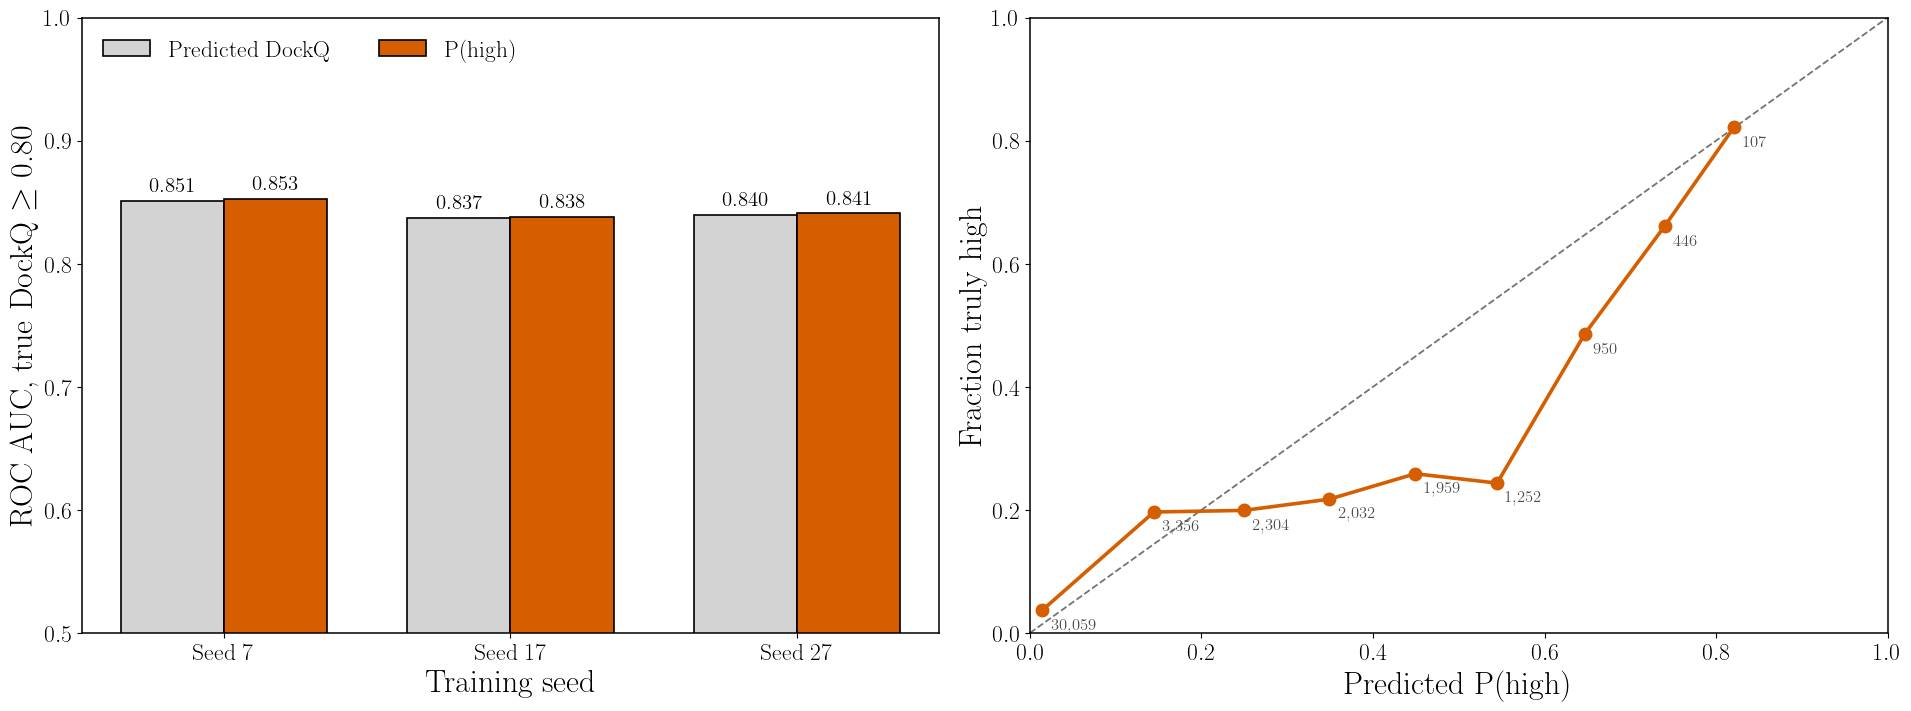

In [7]:
cap = metrics[metrics.config == 'capri_head']
auc = pd.DataFrame({'Predicted DockQ': cap.high_auc_scalar.to_numpy(), 'P(high)': cap.high_auc_p_high.to_numpy()},
                   index=cap.seed)
display(auc.round(3))
pooled = pd.concat([predictions['capri_head', s] for s in SEEDS])
bins = np.linspace(0, 1, 11)
rel = pooled.groupby(pd.cut(pooled.p_high, bins, include_lowest=True), observed=True).agg(
    p=('p_high', 'mean'), frac=('true_target', lambda v: (v >= .8).mean()), n=('p_high', 'size'))
display(rel.round(3))

fig, (ax, axr) = plt.subplots(1, 2, figsize=(19, 7), constrained_layout=True)
xb = np.arange(len(SEEDS)); wb = .36
for k, (name, color) in enumerate([('Predicted DockQ', 'lightgray'), ('P(high)', COLOR['capri_head'])]):
    bars = ax.bar(xb + (k - .5) * wb, auc[name], wb, color=color, edgecolor='black', lw=1.2, label=name)
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in auc[name]], padding=4, fontsize=15)
ax.set_xticks(xb, [f'Seed {s}' for s in SEEDS]); ax.set_ylim(.5, 1)
ax.set_ylabel(r'ROC AUC, true DockQ $\geq$ 0.80'); ax.set_xlabel('Training seed')
ax.legend(frameon=False, loc='upper left', ncol=2)
axr.plot([0, 1], [0, 1], color='0.45', ls='--', lw=1.3)
axr.plot(rel.p, rel.frac, marker='o', ms=9, lw=2.6, color=COLOR['capri_head'])
for _, r in rel.iterrows():
    axr.annotate(f'{int(r.n):,}', (r.p, r.frac), textcoords='offset points', xytext=(6, -14), fontsize=12, color='0.3')
axr.set(xlim=(0, 1), ylim=(0, 1)); axr.set_xlabel('Predicted P(high)'); axr.set_ylabel('Fraction truly high')
save(fig, 'capri_head_p_high')

## Observed vs predicted DockQ

Each panel pools the best checkpoints of the three seeds of one configuration. Shading is the log count of
decoys; the dashed diagonal is perfect agreement; dotted lines mark the CAPRI thresholds; the coloured line is the
mean prediction in bins of observed DockQ.

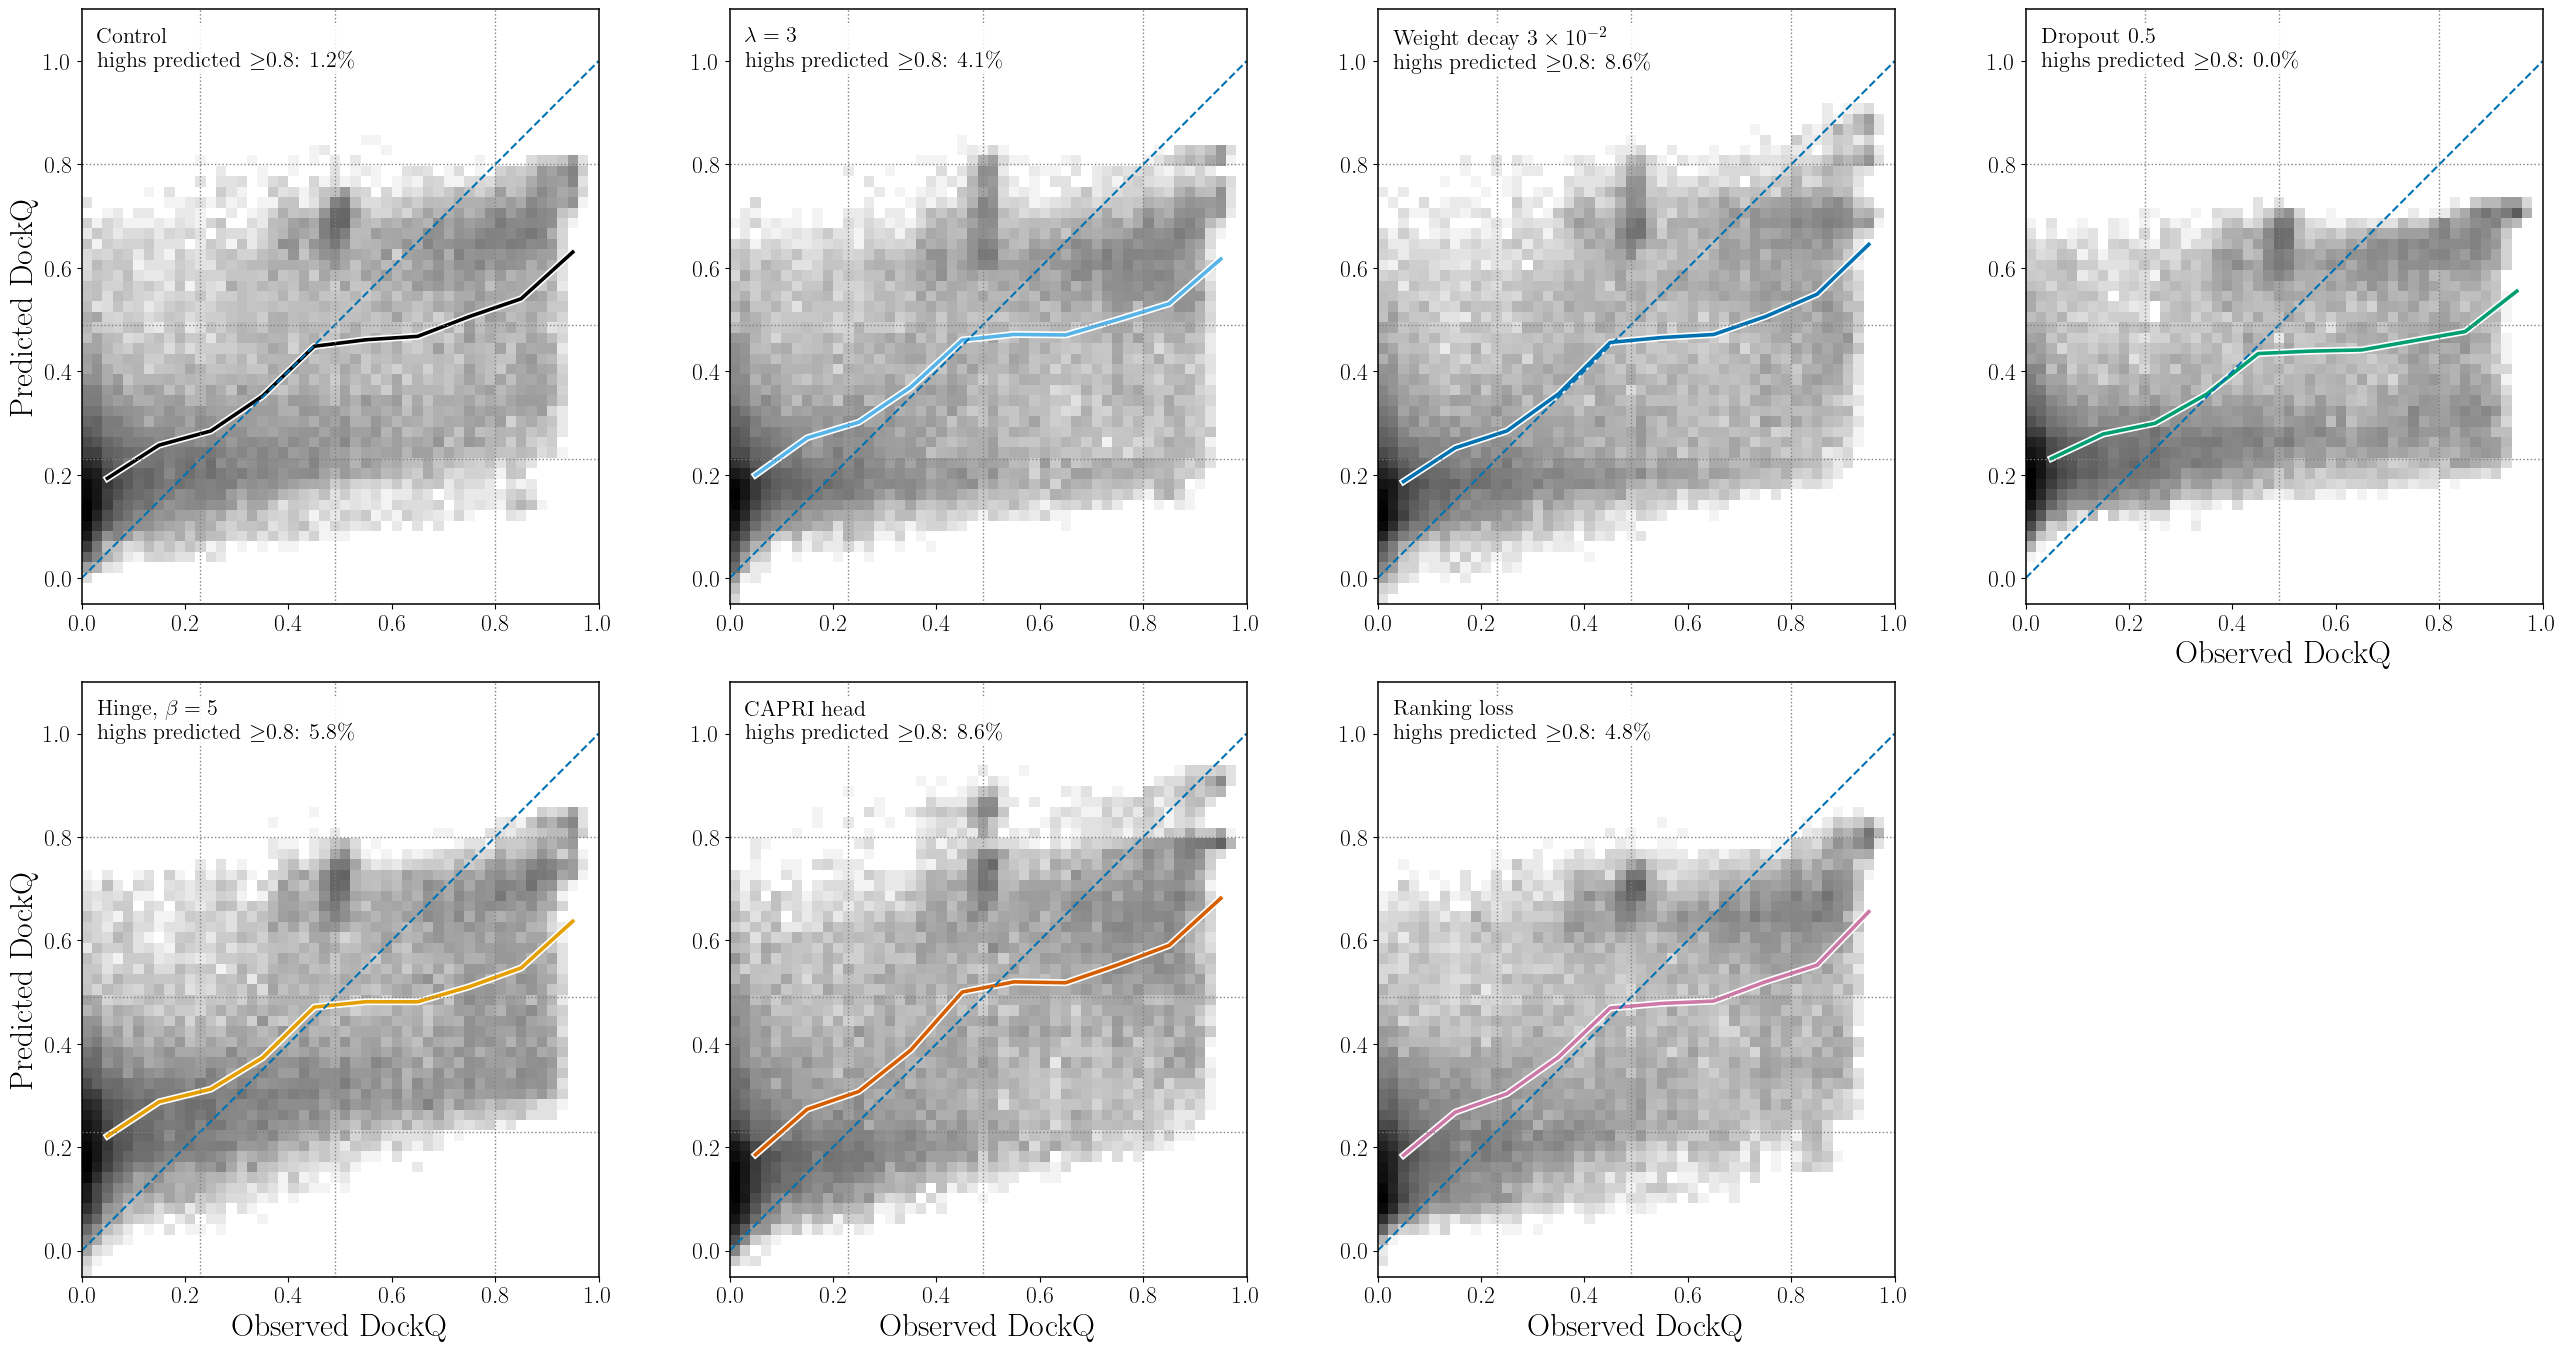

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(26, 13.4), sharex=True, sharey=True, constrained_layout=True)
edges = np.linspace(0, 1, 11); mids = (edges[:-1] + edges[1:]) / 2
for ax, config in zip(axes.flat, CONFIGS):
    pr = pd.concat([predictions[config, s] for s in SEEDS])
    ax.hist2d(pr.true_target, pr.predicted_target.clip(-.05, 1.1), bins=[np.linspace(0, 1, 51), np.linspace(-.05, 1.1, 58)],
              cmap='Greys', norm=LogNorm(vmin=1), rasterized=True)
    means = pr.groupby(pd.cut(pr.true_target, edges, include_lowest=True), observed=False).predicted_target.mean()
    ax.plot(mids, means.to_numpy(), color='white', lw=5); ax.plot(mids, means.to_numpy(), color=COLOR[config], lw=2.6)
    ax.plot([0, 1], [0, 1], color='#0072B2', ls='--', lw=1.5)
    for t in CAPRI:
        ax.axvline(t, color='0.5', ls=':', lw=1); ax.axhline(t, color='0.5', ls=':', lw=1)
    hi = pr.true_target >= .8
    ax.text(.03, .97, LABEL[config] + '\n' + rf'highs predicted $\geq$0.8: {(pr.predicted_target[hi] >= .8).mean() * 100:.1f}\%',
            transform=ax.transAxes, va='top', fontsize=16, bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=2))
    ax.set(xlim=(0, 1), ylim=(-.05, 1.1)); ax.set_aspect('equal', adjustable='box')
    ax.tick_params(labelbottom=True, labelleft=True)
axes.flat[-1].set_visible(False)
for ax in axes[-1]: ax.set_xlabel('Observed DockQ')
axes[0, -1].set_xlabel('Observed DockQ')
for ax in axes[:, 0]: ax.set_ylabel('Predicted DockQ')
save(fig, 'observed_vs_predicted_by_config')

### Per target: control vs the two configurations that beat it at the best checkpoint

Seed 17 for all three, every validation target. Control in black; each comparison configuration in its colour.
Shared axes; the dashed line is perfect agreement; annotations give within-target Spearman $\rho$.

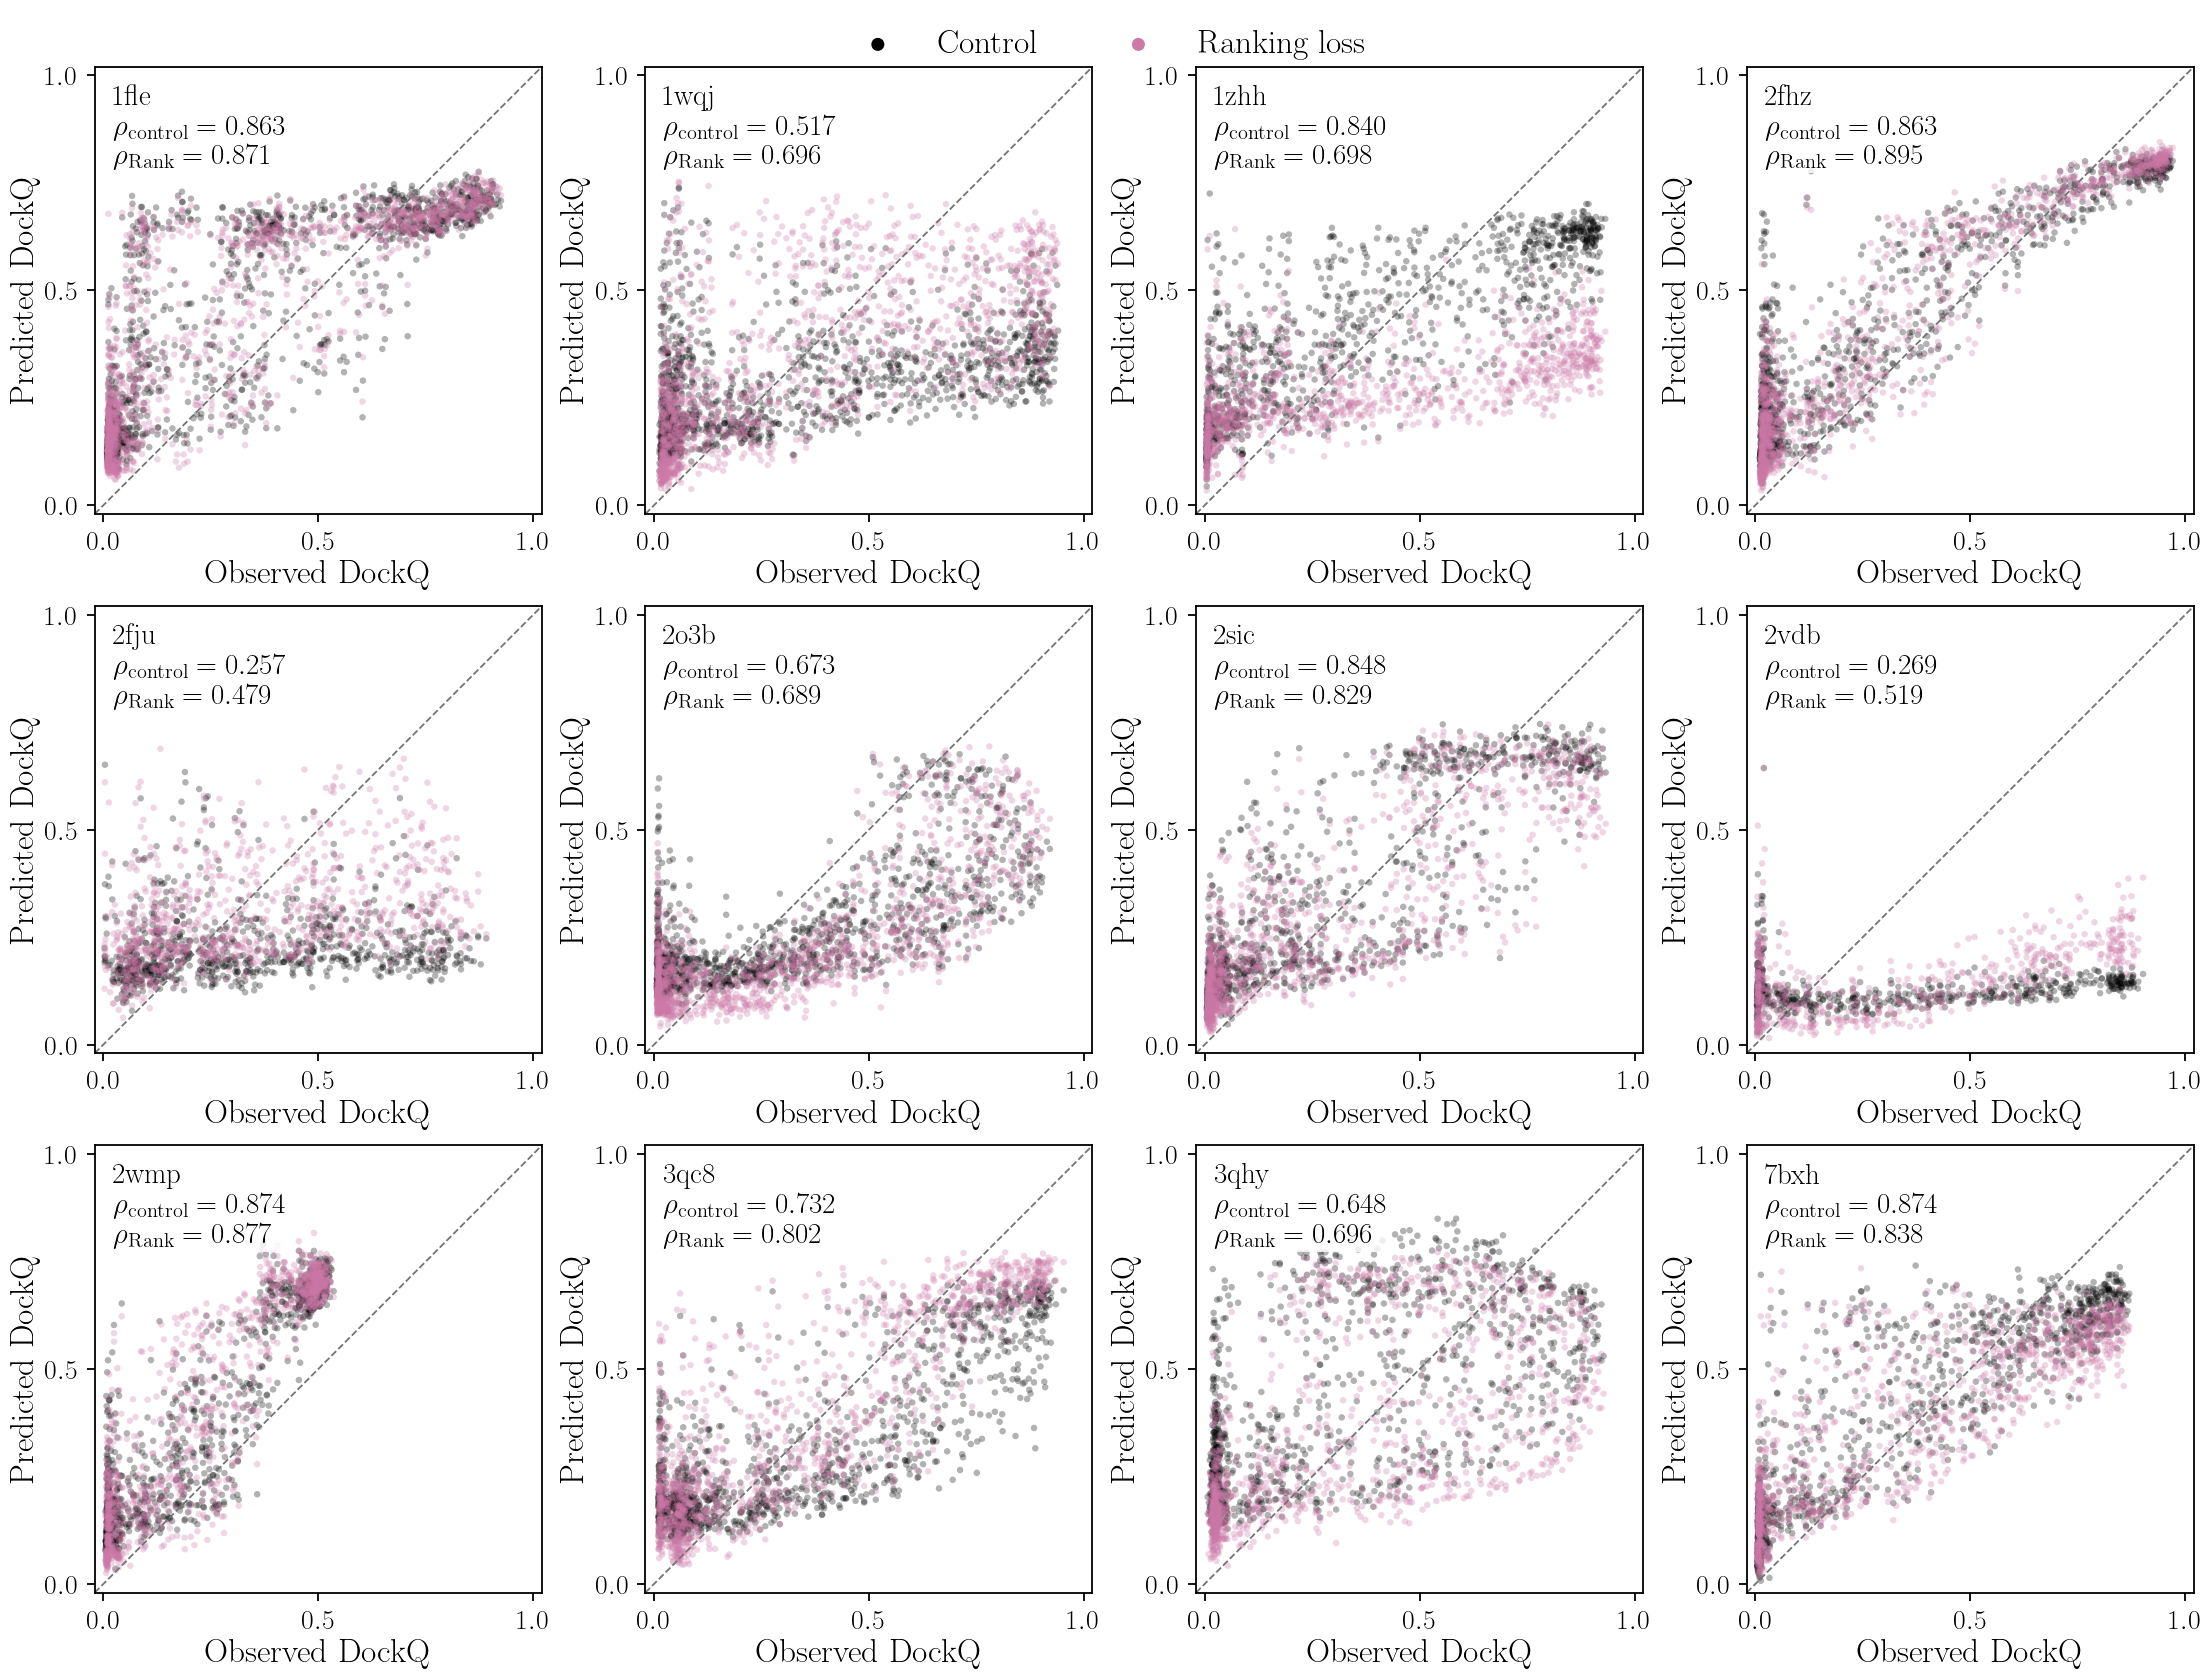

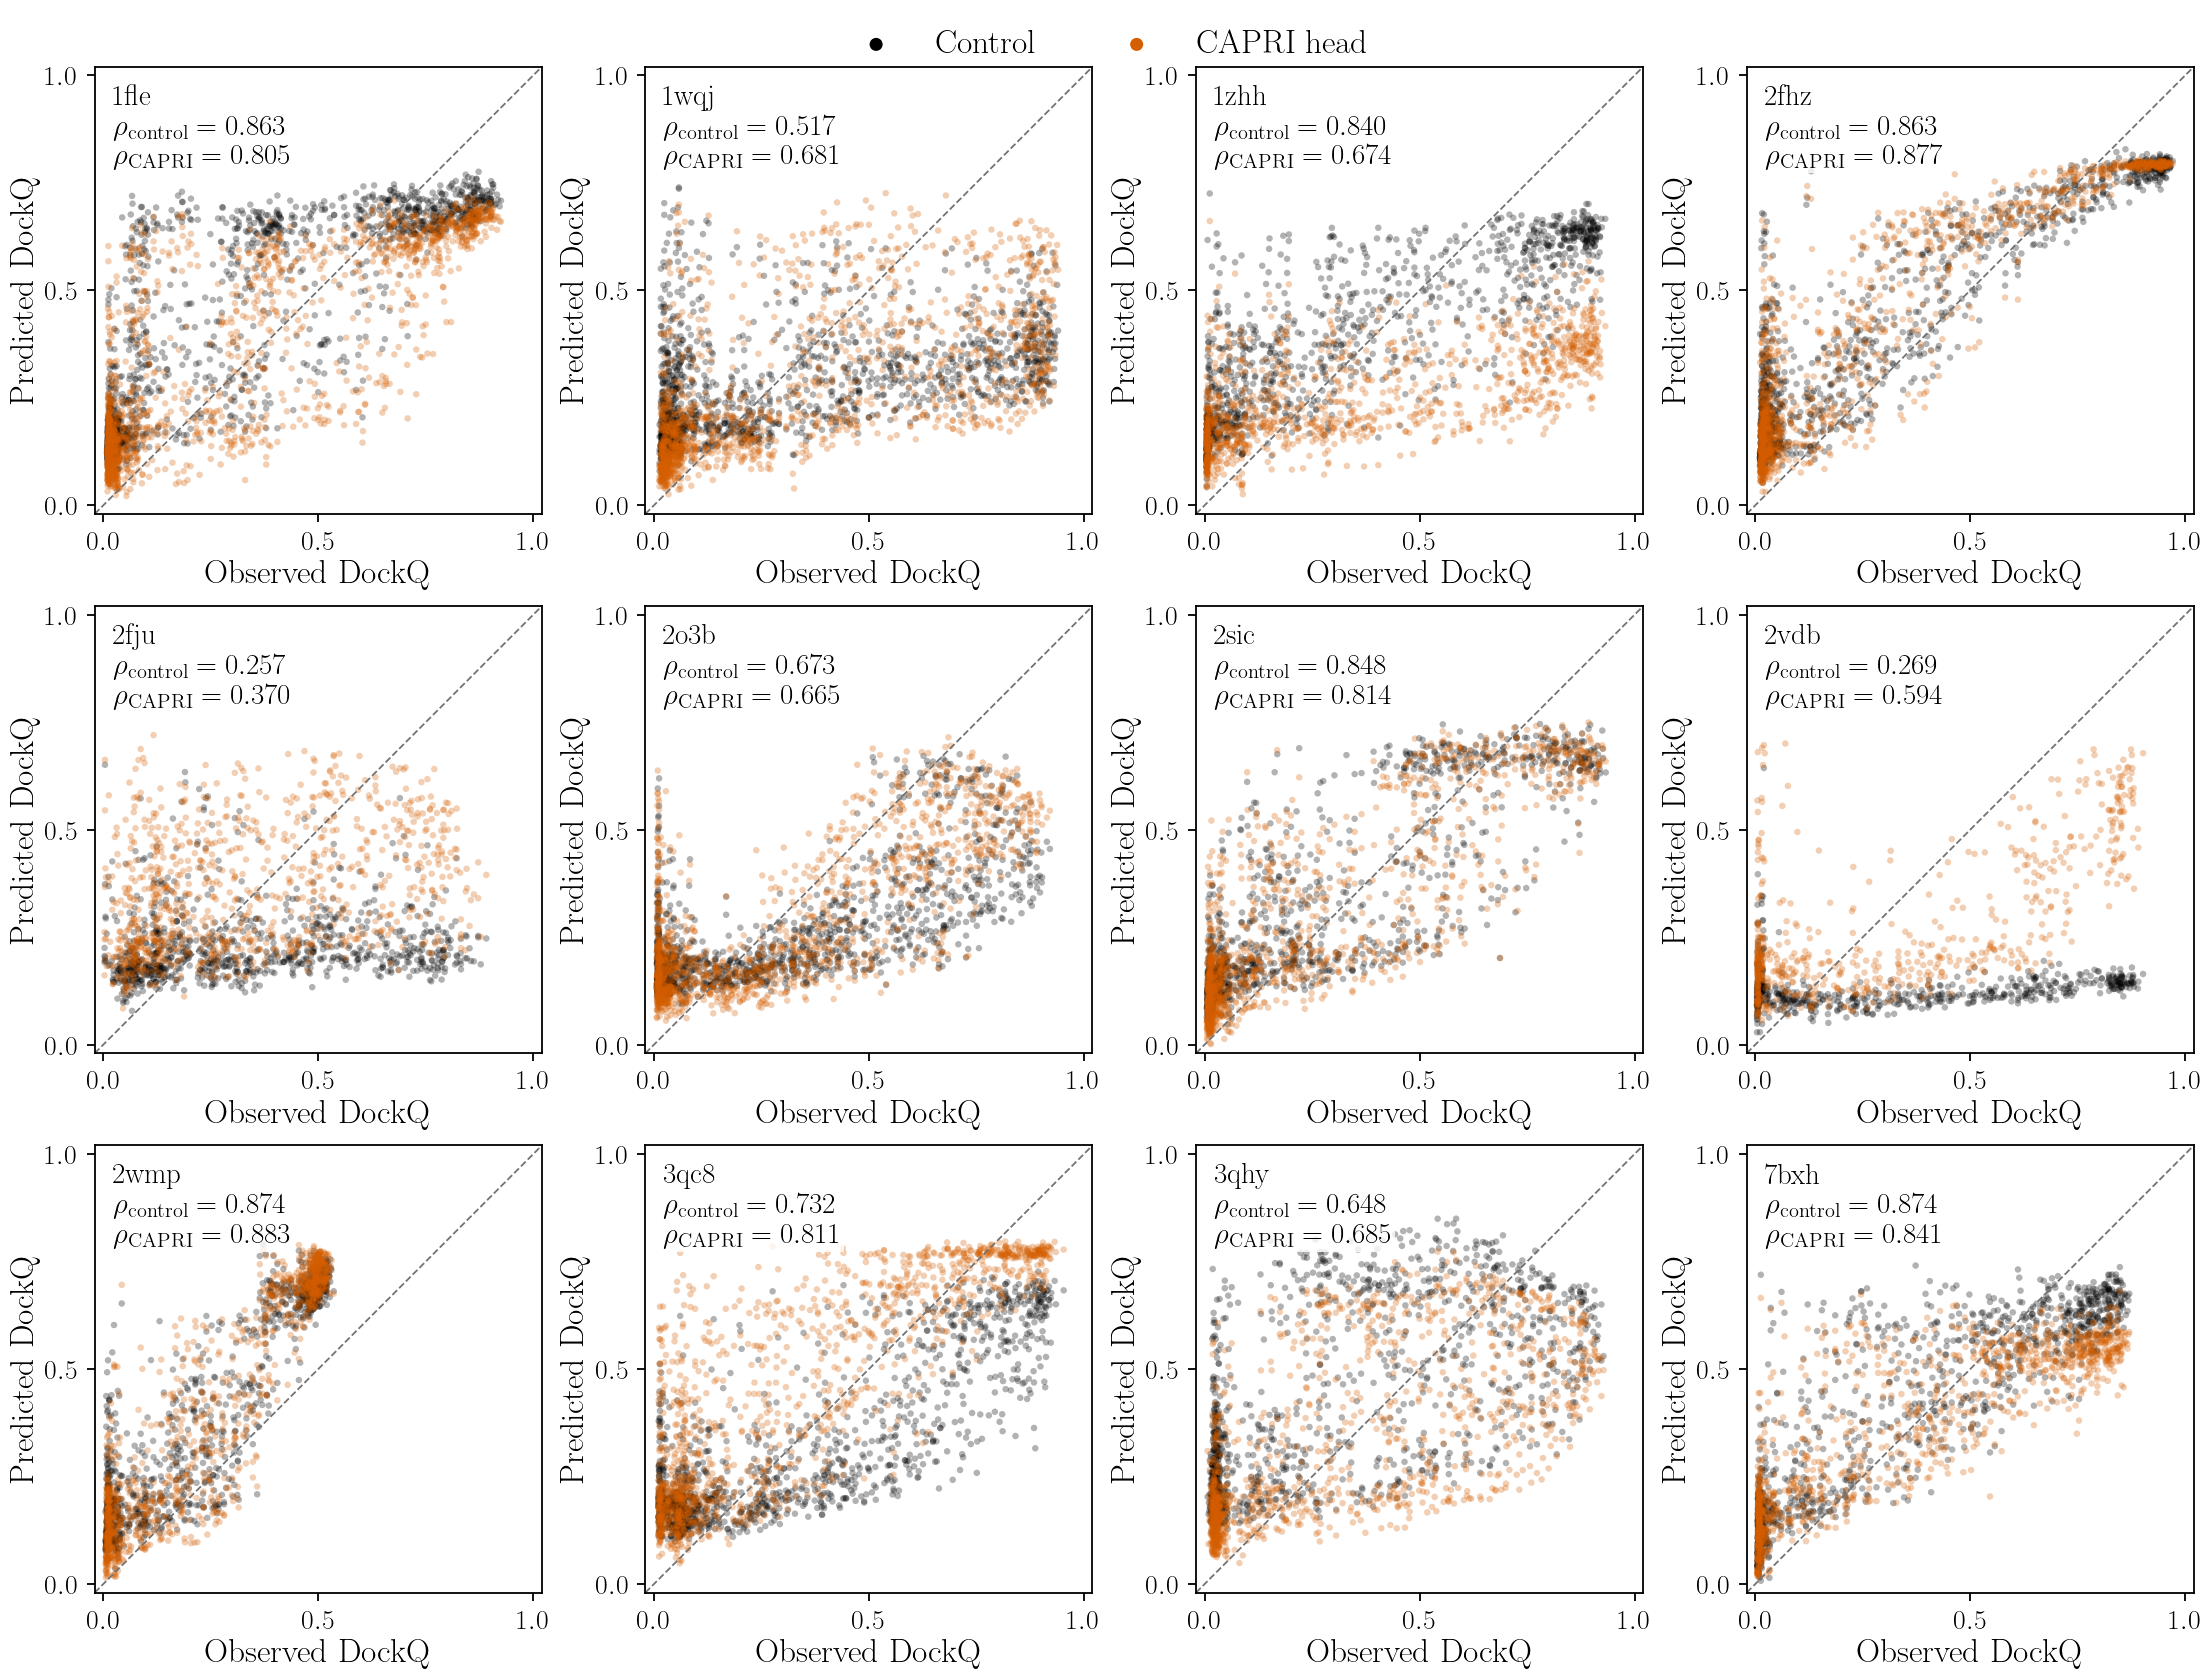

In [9]:
PANEL_SEED = 17
for other in ['rank', 'capri_head']:
    frames = {'control': predictions['control', PANEL_SEED], other: predictions[other, PANEL_SEED]}
    axis_low = min(0.0, *(f.predicted_target.min() for f in frames.values())) - 0.02
    axis_high = max(1.0, *(f.predicted_target.max() for f in frames.values())) + 0.02
    with mpl.rc_context({'axes.labelsize': 24, 'xtick.labelsize': 20, 'ytick.labelsize': 20}):
        fig, axes = plt.subplots(3, 4, figsize=(22, 16.8), sharex=True, sharey=True, constrained_layout=True)
        for ax, target in zip(axes.flat, targets):
            rhos = {}
            for key, frame in frames.items():
                g = frame.loc[frame.target_id.eq(target)]
                rhos[key] = spearmanr(g.true_target, g.predicted_target).statistic
                ax.scatter(g.true_target, g.predicted_target, color=COLOR[key], alpha=0.30, s=22, edgecolors='none',
                           rasterized=True, label=LABEL[key])
            ax.plot([axis_low, axis_high], [axis_low, axis_high], color='0.45', ls='--', lw=1.3)
            ax.text(0.04, 0.96, target + '\n' + rf"$\rho_{{\mathrm{{control}}}} = {rhos['control']:.3f}$" + '\n'
                    + rf"$\rho_{{\mathrm{{{SHORT[other]}}}}} = {rhos[other]:.3f}$", transform=ax.transAxes, ha='left',
                    va='top', fontsize=21, bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
            ax.set(xlim=(axis_low, axis_high), ylim=(axis_low, axis_high), xlabel='Observed DockQ', ylabel='Predicted DockQ')
            ax.set_xticks([0, .5, 1]); ax.set_yticks([0, .5, 1]); ax.set_aspect('equal', adjustable='box')
            ax.tick_params(labelbottom=True, labelleft=True, length=6, width=1.3, pad=6)
            for spine in ax.spines.values():
                spine.set_linewidth(1.3)
        legend = fig.legend(*axes.flat[0].get_legend_handles_labels(), loc='outside upper center', ncol=2, fontsize=24,
                            frameon=False, markerscale=2)
        for handle in legend.legend_handles:
            handle.set_alpha(1.0)
        save(fig, f'per_target_control_vs_{other}_seed{PANEL_SEED}')

## The CAPRI head's late degradation

The CAPRI head gives the best checkpoint but the largest rise afterwards. Its training cross-entropy keeps
falling while validation cross-entropy and validation DockQ MSE climb, the same memorization signature the
cause ablation traced to the adaptive weighting: a second label-driven loss adds DockQ-related pull on the
encoder.

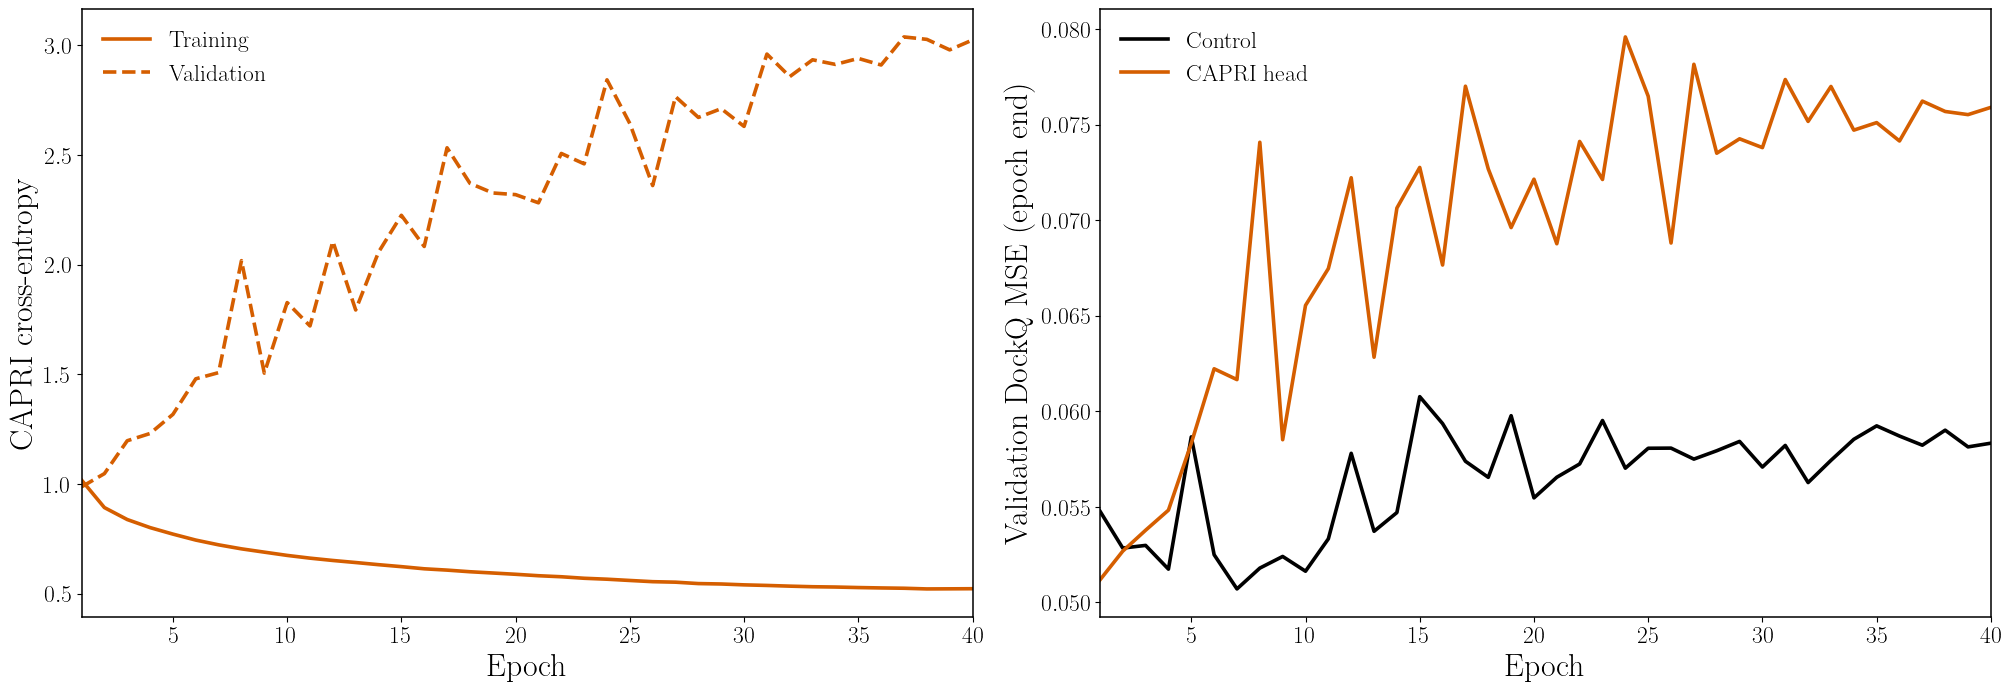

In [10]:
hc = history[history.config == 'capri_head'].groupby('epoch')[['train_capri_ce', 'val_capri_ce', 'val_target_mse']].mean()
hctrl = history[history.config == 'control'].groupby('epoch').val_target_mse.mean()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(20, 6.8), constrained_layout=True)
a1.plot(hc.index, hc.train_capri_ce, color=COLOR['capri_head'], lw=2.6, label='Training')
a1.plot(hc.index, hc.val_capri_ce, color=COLOR['capri_head'], lw=2.6, ls='--', label='Validation')
a1.set_xlabel('Epoch'); a1.set_ylabel('CAPRI cross-entropy'); a1.legend(frameon=False)
a2.plot(hctrl.index, hctrl.values, color='black', lw=2.6, label='Control')
a2.plot(hc.index, hc.val_target_mse, color=COLOR['capri_head'], lw=2.6, label='CAPRI head')
a2.set_xlabel('Epoch'); a2.set_ylabel('Validation DockQ MSE (epoch end)'); a2.legend(frameon=False)
for ax in (a1, a2): ax.set_xlim(1, EPOCHS)
save(fig, 'capri_head_training')

## Readout

In [11]:
def ms(c, col, f='.4f', scale=1):
    return f"{agg.loc[c, (col, 'mean')] * scale:{f}} ± {agg.loc[c, (col, 'std')] * scale:{f}}"
lines = ['| config | best MSE | end MSE | best epoch | ⟨ρ⟩ | top-1 | high recall | high precision | high bias |',
         '|---|---|---|---|---|---|---|---|---|']
for c in CONFIGS:
    lines.append(f"| {c} | {ms(c, 'mse')} | {ms(c, 'late')} | {ms(c, 'best_epoch', '.1f')} | {ms(c, 'macro_rho', '.3f')} "
                 f"| {ms(c, 'top1', '.3f')} | {ms(c, 'high_recall', '.1f', 100)}% | "
                 f"{agg.loc[c, ('high_precision', 'mean')] * 100:.0f}% | {ms(c, 'high_bias', '.3f')} |")
e = eff.set_index(['config', 'metric'])
lines += ['', 'Paired vs control over 12 targets (95% bootstrap CI; positive favours the configuration):']
for c in CONFIGS[1:]:
    lines.append(f"- {c}: −ΔMSE {e.loc[(c, 'mse'), 'mean']:+.4f} [{e.loc[(c, 'mse'), 'lo']:+.4f}, {e.loc[(c, 'mse'), 'hi']:+.4f}]; "
                 f"Δρ {e.loc[(c, 'rho'), 'mean']:+.3f} [{e.loc[(c, 'rho'), 'lo']:+.3f}, {e.loc[(c, 'rho'), 'hi']:+.3f}]")
text = '\n'.join(lines); display(Markdown(text)); (EXPORT / 'readout.md').write_text(text)

| config | best MSE | end MSE | best epoch | ⟨ρ⟩ | top-1 | high recall | high precision | high bias |
|---|---|---|---|---|---|---|---|---|
| control | 0.0482 ± 0.0021 | 0.0585 ± 0.0025 | 6.5 ± 5.4 | 0.705 ± 0.020 | 0.536 ± 0.069 | 1.2 ± 1.3% | 57% | -0.307 ± 0.021 |
| lambda3 | 0.0506 ± 0.0019 | 0.0562 ± 0.0031 | 15.8 ± 2.8 | 0.692 ± 0.025 | 0.516 ± 0.040 | 4.1 ± 7.1% | 33% | -0.317 ± 0.039 |
| wd3e-2 | 0.0481 ± 0.0021 | 0.0578 ± 0.0062 | 10.1 ± 11.4 | 0.713 ± 0.020 | 0.486 ± 0.092 | 8.6 ± 7.7% | 79% | -0.297 ± 0.042 |
| dropout05 | 0.0567 ± 0.0007 | 0.0630 ± 0.0043 | 9.0 ± 6.8 | 0.675 ± 0.005 | 0.424 ± 0.048 | 0.0 ± 0.0% | nan% | -0.373 ± 0.016 |
| hinge_max_b5 | 0.0498 ± 0.0020 | 0.0608 ± 0.0021 | 3.3 ± 1.4 | 0.714 ± 0.019 | 0.401 ± 0.023 | 5.8 ± 6.8% | 60% | -0.300 ± 0.030 |
| capri_head | 0.0462 ± 0.0010 | 0.0761 ± 0.0090 | 2.9 ± 1.9 | 0.724 ± 0.017 | 0.497 ± 0.086 | 8.6 ± 13.5% | 76% | -0.257 ± 0.039 |
| rank | 0.0465 ± 0.0029 | 0.0591 ± 0.0035 | 9.0 ± 6.3 | 0.732 ± 0.036 | 0.490 ± 0.043 | 4.8 ± 2.2% | 93% | -0.292 ± 0.033 |

Paired vs control over 12 targets (95% bootstrap CI; positive favours the configuration):
- lambda3: −ΔMSE -0.0026 [-0.0061, +0.0008]; Δρ -0.013 [-0.043, +0.012]
- wd3e-2: −ΔMSE +0.0008 [-0.0025, +0.0053]; Δρ +0.008 [-0.015, +0.038]
- dropout05: −ΔMSE -0.0073 [-0.0147, -0.0003]; Δρ -0.029 [-0.079, +0.014]
- hinge_max_b5: −ΔMSE -0.0002 [-0.0056, +0.0065]; Δρ +0.009 [-0.017, +0.041]
- capri_head: −ΔMSE +0.0033 [-0.0044, +0.0115]; Δρ +0.019 [-0.006, +0.046]
- rank: −ΔMSE +0.0011 [-0.0031, +0.0052]; Δρ +0.027 [+0.005, +0.050]

1575

## Interpretation

**Question 1 -- does validation keep falling over 40 epochs? No configuration does.**

- Every configuration reaches its best checkpoint in the first 3--16 epochs. After that, validation MSE rises
  modestly and then levels off: the slope over epochs 20--40 is close to zero everywhere (at most
  $\sim$0.0002 per epoch, for the CAPRI head). The control gives back about 0.010 between its best (0.048,
  epoch $\sim$7) and the end (0.059), almost all of it before epoch 20.
- **$\lambda = 3$** behaves most like the goal: its best comes latest (epoch $\sim$16) and it ends lowest (0.056).
  But that best is worse (0.051 vs 0.048), so it trades peak accuracy for stability rather than improving both.
- **Weight decay $3\times10^{-2}$** ties the control on every measure (one seed kept improving to the end, the
  other two did not).
- **Dropout 0.5** is worse throughout (best 0.057; significantly worse MSE and top-1 than the control).

**Question 2 -- high-DockQ accuracy. Two additions help at the best checkpoint; one stays stable.**

- **Ranking loss** is the only change with a clear paired improvement: within-target $\rho$ +0.027 [+0.005,
  +0.050], better on 9 of 12 targets, with MSE tied (0.0465 vs 0.0482) and a training curve that ends like the
  control's. Its gains are largest on the weakest targets. Its decoys predicted $\geq 0.80$ are 93\% truly high,
  but it still predicts few of them (5\% of true highs).
- **CAPRI head** has the best checkpoint: lowest MSE (0.046), the smallest high-DockQ under-prediction
  ($-0.26$ vs $-0.31$), the highest high-quality recall (9\% vs 1\%) at 76\% precision, and $\rho$ +0.019
  (CI just includes 0). But it peaks at epoch $\sim$3 and then degrades the most (end MSE 0.076): its
  validation cross-entropy rises while training cross-entropy falls, a second label-driven loss adding the kind of
  pull on the encoder that drives memorization. Its P(high) is not a better detector of high-quality decoys than
  the scalar prediction (ROC AUC 0.84 for both), and it is over-confident in the 0.3--0.6 range. The benefit is
  that the extra head improved the shared representation the DockQ head reads, not the probability itself.
- **Hinge, $\beta = 5$** does not help: MSE tied, high-DockQ bias essentially unchanged, poor decoys predicted
  higher (+0.17 vs +0.15), and top-1 significantly worse ($-0.135$).
- High-quality decoys remain under-predicted by 0.26--0.37 in every configuration. No single change has fixed the
  compression; the best ones narrow it.
- **Top-1 does not improve anywhere** (every configuration is at or below the control's 0.54). The control's top-1
  has the largest seed spread, so this is partly noise, but none of the changes moves selection of the single best
  decoy.

**Taken together.** The ranking loss is the most robust gain (better ranking, stable training, no MSE cost). The
CAPRI head shows that an auxiliary class signal improves the best checkpoint markedly but needs the same kind of
restraint fixed weights gave the DockQ term, for example a smaller weight or decaying it after the first epochs.
$\lambda = 3$ is the only lever that moved the best checkpoint later. Natural next combinations: ranking loss +
CAPRI head (lower weight), and ranking loss + $\lambda = 3$.

Caveats: three seeds; 12 validation targets that have now informed several rounds of choices; best-checkpoint
numbers are selected on the same validation set they are reported on. The test split is untouched.